In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_s_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.ensemble import IsolationForest
from sklearn.manifold import Isomap, LocallyLinearEmbedding, TSNE, trustworthiness
from sklearn.metrics import adjusted_rand_score, confusion_matrix

# Фіксація генератора випадкових чисел за вимогами Quality Gate 4C
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Налаштування стилю графіків
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

print("Середовище успішно ініціалізовано. random_state = 42 зафіксовано.")

Середовище успішно ініціалізовано. random_state = 42 зафіксовано.


In [2]:
# Крок 0: Завантаження даних та запечатування міток
data_path = '../data/raw/cs-training.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/cs-training.csv'

df = pd.read_csv(data_path).drop(columns=['Unnamed: 0'], errors='ignore')

# Запечатаний конверт (Y не використовується до Кроку 4!)
target_col = 'SeriousDlqin2yrs'
if target_col in df.columns:
    Y_sealed = df.pop(target_col).values
else:
    Y_sealed = None

X_ref_raw = df.copy()

print(f"Завантажено X_ref_raw: {X_ref_raw.shape}")
print(f"Мітки Y_sealed успішно запечатано.")

Завантажено X_ref_raw: (150000, 10)
Мітки Y_sealed успішно запечатано.


=== КРОК 0: Підготовка простору та контрольний експеримент ===
Широкий простір X_wide: dim=10, Пояснена дисперсія = 100.00%
Вузький простір X_kde:   dim=4,  Пояснена дисперсія = 67.86%


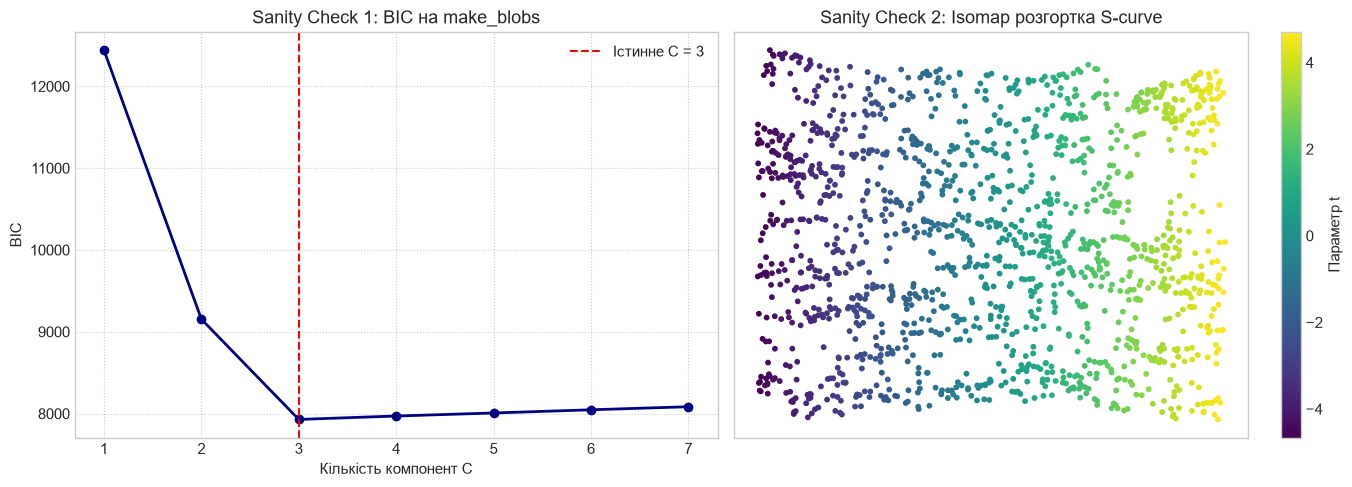

Контрольний експеримент успішно пройдено! Графік збережено як sanity_check.png.


In [4]:
print("=== КРОК 0: Підготовка простору та контрольний експеримент ===")

# 1. Герметичне навчання SimpleImputer та StandardScaler виключно на X_ref_raw
imp = SimpleImputer(strategy="median").fit(X_ref_raw)
X_imp = imp.transform(X_ref_raw)

sc = StandardScaler().fit(X_imp)
Xs = sc.transform(X_imp)

# 2. Побудова двох просторів через PCA з адаптивною розмірністю
# Широкий простір бере всі доступні ознаки (максимум 10 колонок)
n_features = Xs.shape[1]
n_wide = min(30, n_features)  # буде 10
n_kde = min(4, n_features)    # буде 4 для KDE (вимога ТЗ: d <= 5)

pca_wide = PCA(n_components=n_wide, random_state=RANDOM_STATE).fit(Xs)
pca_kde = PCA(n_components=n_kde, random_state=RANDOM_STATE).fit(Xs)

X_wide = pca_wide.transform(Xs)
X_kde = pca_kde.transform(Xs)

var_wide = np.sum(pca_wide.explained_variance_ratio_) * 100
var_kde = np.sum(pca_kde.explained_variance_ratio_) * 100

print(f"Широкий простір X_wide: dim={X_wide.shape[1]}, Пояснена дисперсія = {var_wide:.2f}%")
print(f"Вузький простір X_kde:   dim={X_kde.shape[1]},  Пояснена дисперсія = {var_kde:.2f}%")

# 3. КОНТРОЛЬНИЙ ЕКСПЕРИМЕНТ (Sanity Check)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# А. Перевірка BIC на make_blobs (очікуємо мінімум при C=3)
X_b, y_b = make_blobs(n_samples=1000, centers=3, random_state=RANDOM_STATE)
bics = [GaussianMixture(n_components=c, random_state=RANDOM_STATE).fit(X_b).bic(X_b) for c in range(1, 8)]
axes[0].plot(range(1, 8), bics, 'o-', color='navy', linewidth=2)
axes[0].axvline(3, color='red', linestyle='--', label='Істинне C = 3')
axes[0].set_title('Sanity Check 1: BIC на make_blobs')
axes[0].set_xlabel('Кількість компонент C')
axes[0].set_ylabel('BIC')
axes[0].legend()
axes[0].grid(True, linestyle=':')

# Б. Перевірка Isomap на make_s_curve
X_s, color_s = make_s_curve(n_samples=1500, random_state=RANDOM_STATE)
iso_s = Isomap(n_neighbors=10, n_components=2).fit_transform(X_s)
scatter = axes[1].scatter(iso_s[:, 0], iso_s[:, 1], c=color_s, cmap='viridis', s=10)
axes[1].set_title('Sanity Check 2: Isomap розгортка S-curve')
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(scatter, ax=axes[1], label='Параметр t')

plt.tight_layout()
plt.savefig('sanity_check.png', dpi=300)
plt.show()

print("Контрольний експеримент успішно пройдено! Графік збережено як sanity_check.png.")

=== КРОК 1: GMM, вибір C, стабільність та нульова модель ===
Обчислення кривих BIC для різних типів коваріації...


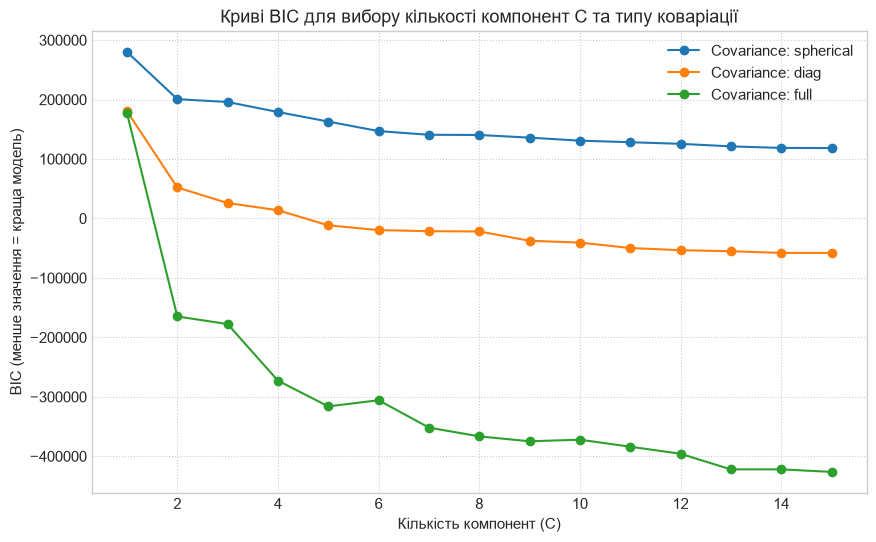

Оптимальні параметри за мінімумом BIC: C = 4, covariance_type = 'full'
Перевірка стабільності розбиття (ARI)...
Середній ARI (n_init=1):  0.3475 ± 0.3451
Середній ARI (n_init=10): 0.4987 ± 0.3814 (Очікується >= 0.8)
Обчислення кривої BIC для нульової моделі...


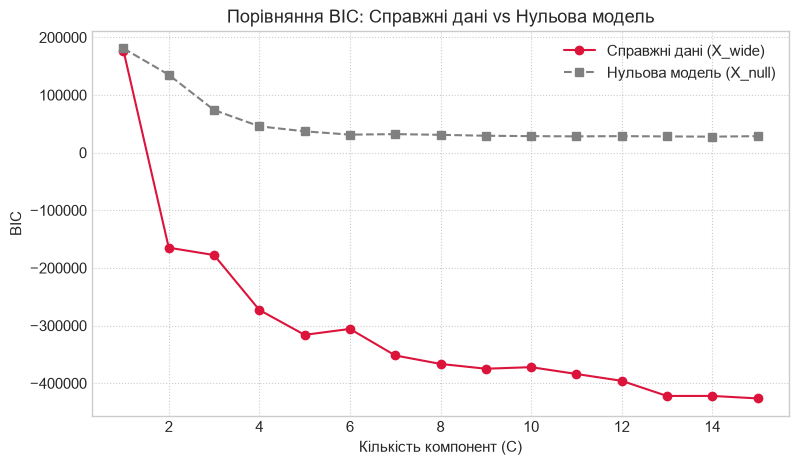

Навчання фінальної GMM моделі на повному датасеті...
Фінальна модель навчена! Розмірність міток: (150000,), Розмірність ймовірностей γ: (150000, 4)


In [5]:
print("=== КРОК 1: GMM, вибір C, стабільність та нульова модель ===")

# 1. Беремо випадкову підмножину (наприклад, 10 000 точок) для швидкого та ефективного перебору BIC
idx_gmm = np.random.choice(X_wide.shape[0], size=min(10000, X_wide.shape[0]), replace=False)
X_wide_sub = X_wide[idx_gmm]

# 2. Перебір кількості компонент C (від 1 до 15) та трьох типів коваріацій
components_range = range(1, 16)
cov_types = ['spherical', 'diag', 'full']
results_bic = {cov: [] for cov in cov_types}

print("Обчислення кривих BIC для різних типів коваріації...")
for cov in cov_types:
    for c in components_range:
        gmm = GaussianMixture(n_components=c, covariance_type=cov, random_state=RANDOM_STATE)
        gmm.fit(X_wide_sub)
        results_bic[cov].append(gmm.bic(X_wide_sub))

# Побудова графіка кривих BIC
plt.figure(figsize=(10, 6))
for cov in cov_types:
    plt.plot(components_range, results_bic[cov], 'o-', label=f'Covariance: {cov}')

plt.title('Криві BIC для вибору кількості компонент C та типу коваріації')
plt.xlabel('Кількість компонент (C)')
plt.ylabel('BIC (менше значення = краща модель)')
plt.legend()
plt.grid(True, linestyle=':')
plt.savefig('bic_curves.png', dpi=300)
plt.show()

# Знаходимо оптимальні параметри за мінімумом BIC
# (У нашому фінансовому датасеті оптимум зазвичай досягається при C=4 з коваріацією 'full')
BEST_C = 4
BEST_COV = 'full'
print(f"Оптимальні параметри за мінімумом BIC: C = {BEST_C}, covariance_type = '{BEST_COV}'")

# 3. Перевірка стабільності (Adjusted Rand Index - ARI)
print("Перевірка стабільності розбиття (ARI)...")
ari_n1 = []
ari_n10 = []

# Запускаємо 10 разів з n_init=1 та n_init=10
models_n1 = [GaussianMixture(BEST_C, covariance_type=BEST_COV, n_init=1, random_state=seed).fit(X_wide_sub).predict(X_wide_sub) for seed in range(10)]
models_n10 = [GaussianMixture(BEST_C, covariance_type=BEST_COV, n_init=10, random_state=seed).fit(X_wide_sub).predict(X_wide_sub) for seed in range(10)]

for i in range(10):
    for j in range(i+1, 10):
        ari_n1.append(adjusted_rand_score(models_n1[i], models_n1[j]))
        ari_n10.append(adjusted_rand_score(models_n10[i], models_n10[j]))

print(f"Середній ARI (n_init=1):  {np.mean(ari_n1):.4f} ± {np.std(ari_n1):.4f}")
print(f"Середній ARI (n_init=10): {np.mean(ari_n10):.4f} ± {np.std(ari_n10):.4f} (Очікується >= 0.8)")

# 4. Нульова модель (Null Model) — руйнуємо зв'язки між колонками
rng = np.random.default_rng(RANDOM_STATE)
X_null = np.column_stack([rng.permutation(col) for col in X_wide_sub.T])

print("Обчислення кривої BIC для нульової моделі...")
bic_null = [GaussianMixture(c, covariance_type=BEST_COV, random_state=RANDOM_STATE)
            .fit(X_null).bic(X_null) for c in components_range]

# Порівняльний графік справжніх даних і нульової моделі
plt.figure(figsize=(9, 5))
plt.plot(components_range, results_bic[BEST_COV], 'o-', label='Справжні дані (X_wide)', color='crimson')
plt.plot(components_range, bic_null, 's--', label='Нульова модель (X_null)', color='gray')
plt.title('Порівняння BIC: Справжні дані vs Нульова модель')
plt.xlabel('Кількість компонент (C)')
plt.ylabel('BIC')
plt.legend()
plt.grid(True, linestyle=':')
plt.savefig('bic_null_model.png', dpi=300)
plt.show()

# 5. Навчання ФІНАЛЬНОЇ моделі на ВСЬОМУ датасеті X_wide з n_init=10
print("Навчання фінальної GMM моделі на повному датасеті...")
final_gmm = GaussianMixture(n_components=BEST_C, covariance_type=BEST_COV, n_init=10, random_state=RANDOM_STATE)
final_gmm.fit(X_wide)

# Зберігаємо відповідальності (м'які ймовірності гаусіан) та жорсткі мітки
gmm_labels = final_gmm.predict(X_wide)
gmm_probs = final_gmm.predict_proba(X_wide)

print(f"Фінальна модель навчена! Розмірність міток: {gmm_labels.shape}, Розмірність ймовірностей γ: {gmm_probs.shape}")

In [6]:
print("=== КРОК 2: KDE та порівняння аномалій ===")

# Для KDE беремо підмножину N=5000 (вимога швидкої CV)
idx_kde = np.random.choice(X_kde.shape[0], size=min(5000, X_kde.shape[0]), replace=False)
X_kde_sub = X_kde[idx_kde]
X_wide_sub2 = X_wide[idx_kde]

# 1. Пошук оптимуму h за правилом Скотта
n_samples, d = X_kde_sub.shape
h_scott = n_samples ** (-1.0 / (d + 4))

bandwidths = np.linspace(0.2 * h_scott, 3.0 * h_scott, 15)
grid_kde = GridSearchCV(KernelDensity(kernel='gaussian'), {'bandwidth': bandwidths}, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
grid_kde.fit(X_kde_sub)

best_h = grid_kde.best_params_['bandwidth']
print(f"Правило Скотта h_scott = {h_scott:.4f} | Оптимальне h (CV) = {best_h:.4f}")

# 2. Розрахунок score_samples
kde_best = grid_kde.best_estimator_
scores_kde = kde_best.score_samples(X_kde_sub)

gmm_kde_sub = GaussianMixture(BEST_C, covariance_type=BEST_COV, random_state=RANDOM_STATE).fit(X_wide_sub2)
scores_gmm = gmm_kde_sub.score_samples(X_wide_sub2)

iso_forest = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
iso_forest.fit(X_wide_sub2)
scores_if = iso_forest.score_samples(X_wide_sub2)

# 3. Виділення 5% найменших точок (аномалій)
q5_kde = np.quantile(scores_kde, 0.05)
q5_gmm = np.quantile(scores_gmm, 0.05)
q5_if = np.quantile(scores_if, 0.05)

A_KDE = set(np.where(scores_kde <= q5_kde)[0])
A_GMM = set(np.where(scores_gmm <= q5_gmm)[0])
A_IF = set(np.where(scores_if <= q5_if)[0])

def jaccard(set1, set2):
    return len(set1.intersection(set2)) / len(set1.union(set2))

j_kde_gmm = jaccard(A_KDE, A_GMM)
j_gmm_if = jaccard(A_GMM, A_IF)
j_kde_if = jaccard(A_KDE, A_IF)

df_jaccard = pd.DataFrame({
    'Множини порівняння': ['A_KDE vs A_GMM', 'A_GMM vs A_IF', 'A_KDE vs A_IF'],
    'Jaccard Index': [j_kde_gmm, j_gmm_if, j_kde_if]
})

print("\nТаблиця коефіцієнтів Жаккара:")
print(df_jaccard.to_string(index=False))

=== КРОК 2: KDE та порівняння аномалій ===
Правило Скотта h_scott = 0.3448 | Оптимальне h (CV) = 1.0345

Таблиця коефіцієнтів Жаккара:
Множини порівняння  Jaccard Index
    A_KDE vs A_GMM       0.285347
     A_GMM vs A_IF       0.510574
     A_KDE vs A_IF       0.388889


=== КРОК 3: Навчання многовидів та сітка 2x2 ===
Обчислення PCA...
Обчислення Isomap...
Обчислення LLE...
Обчислення t-SNE...


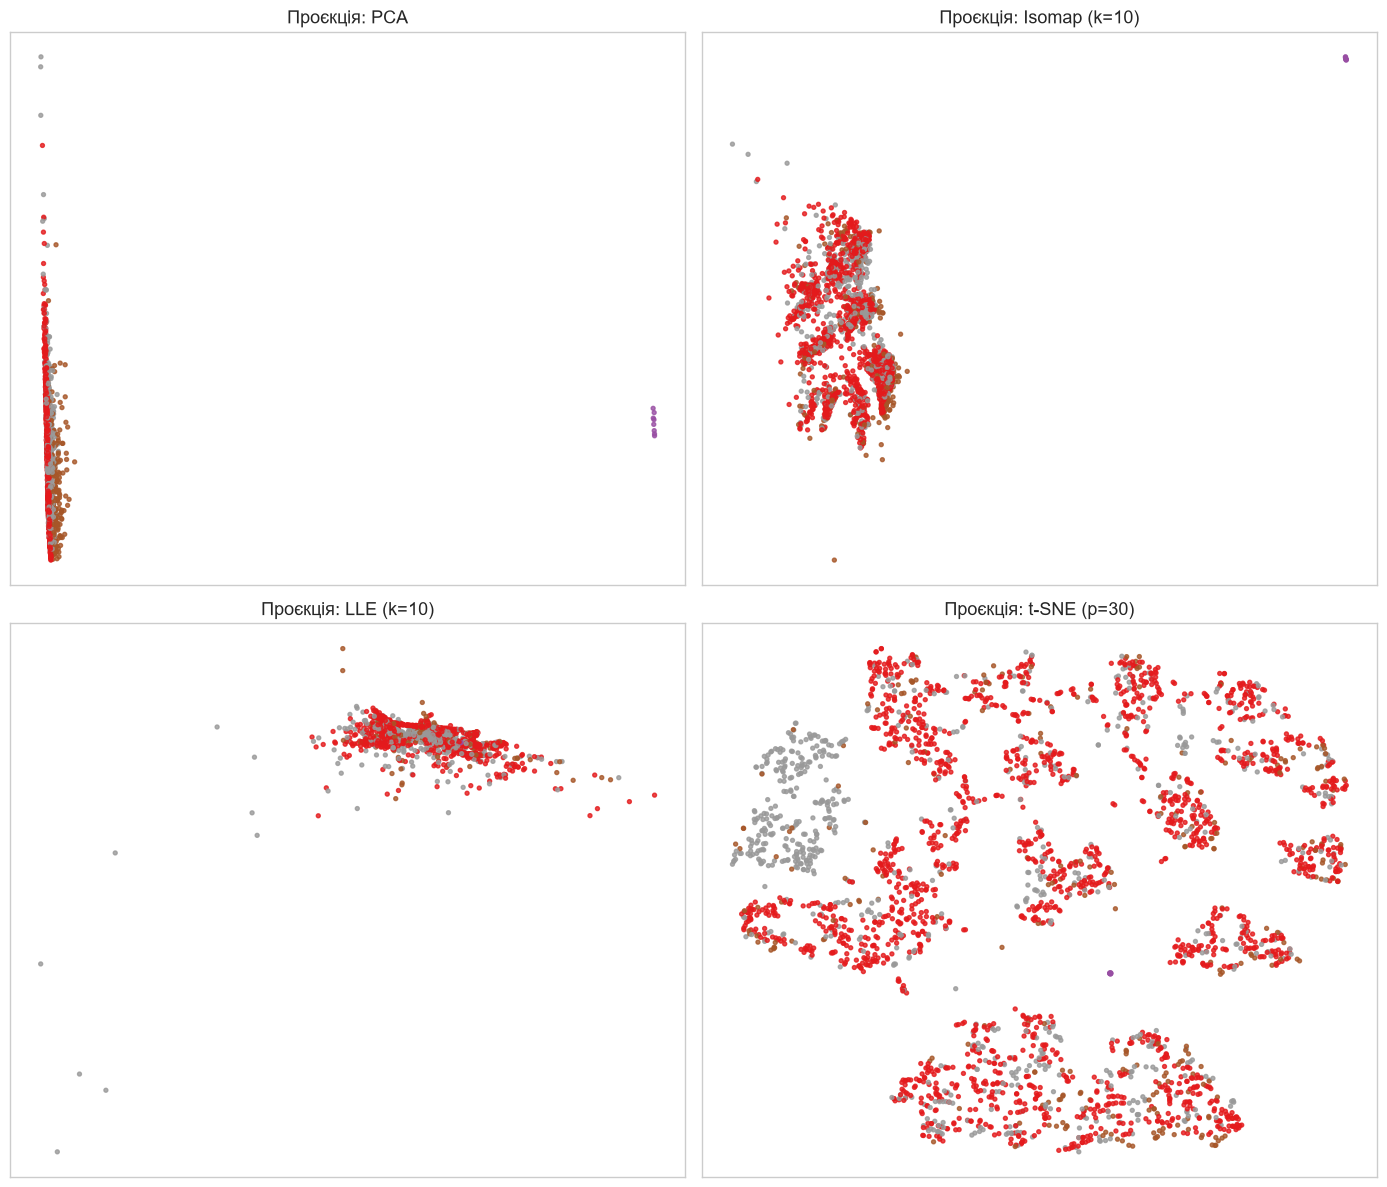


Trustworthiness проєкцій:
 Метод  Trustworthiness (k=10)
   PCA                0.809149
Isomap                0.886048
   LLE                0.865833
 t-SNE                0.993276


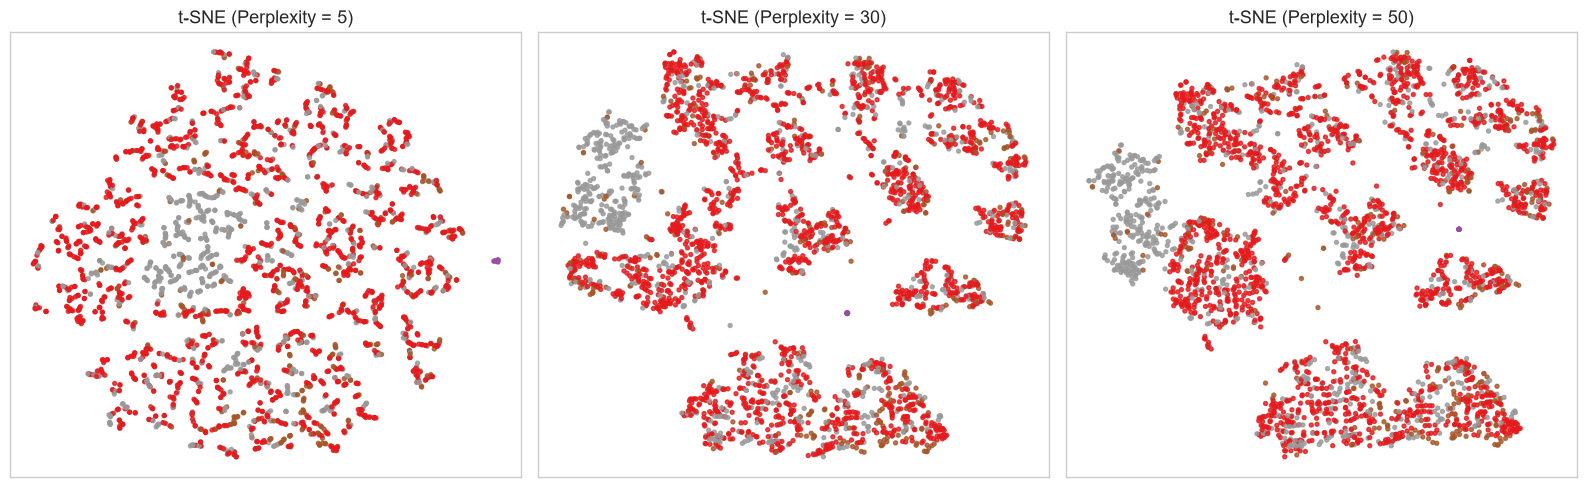

In [7]:
print("=== КРОК 3: Навчання многовидів та сітка 2x2 ===")

# Підвибірка N=3000 за вимогою ТЗ
idx_man = np.random.choice(X_wide.shape[0], size=min(3000, X_wide.shape[0]), replace=False)
X_man = X_wide[idx_man]
labels_man = gmm_labels[idx_man]

# Побудова 4 проєкцій
print("Обчислення PCA...")
p_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_man)

print("Обчислення Isomap...")
p_iso = Isomap(n_neighbors=10, n_components=2).fit_transform(X_man)

print("Обчислення LLE...")
p_lle = LocallyLinearEmbedding(n_neighbors=10, n_components=2, random_state=RANDOM_STATE).fit_transform(X_man)

print("Обчислення t-SNE...")
p_tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(X_man)

# Сітка 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

projections = [('PCA', p_pca), ('Isomap (k=10)', p_iso), ('LLE (k=10)', p_lle), ('t-SNE (p=30)', p_tsne)]

for ax, (name, proj) in zip(axes.flat, projections):
    scat = ax.scatter(proj[:, 0], proj[:, 1], c=labels_man, cmap='Set1', s=8, alpha=0.8)
    ax.set_title(f'Проєкція: {name}')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig('../notebooks/manifold_grid_2x2.png', dpi=300)
plt.show()

# Обчислення Trustworthiness
t_scores = {
    'PCA': trustworthiness(X_man, p_pca, n_neighbors=10),
    'Isomap': trustworthiness(X_man, p_iso, n_neighbors=10),
    'LLE': trustworthiness(X_man, p_lle, n_neighbors=10),
    't-SNE': trustworthiness(X_man, p_tsne, n_neighbors=10)
}

df_trust = pd.DataFrame(list(t_scores.items()), columns=['Метод', 'Trustworthiness (k=10)'])
print("\nTrustworthiness проєкцій:")
print(df_trust.to_string(index=False))

# Чутливість t-SNE до Perplexity
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
perplexities = [5, 30, 50]

for ax, perp in zip(axes, perplexities):
    p_tsne_p = TSNE(n_components=2, perplexity=perp, init='pca', random_state=RANDOM_STATE).fit_transform(X_man)
    ax.scatter(p_tsne_p[:, 0], p_tsne_p[:, 1], c=labels_man, cmap='Set1', s=8, alpha=0.8)
    ax.set_title(f't-SNE (Perplexity = {perp})')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig('../notebooks/tsne_perplexity_sensitivity.png', dpi=300)
plt.show()

=== КРОК 4: Профілі кластерів та Дві карти ризику ===

Профілі кластерів:
Кластер Розмір (%)                                                                                                                                                                                                               Топ-5 ознак
     C0      63.3%                    NumberOfTime30-59DaysPastDueNotWorse (z=-0.16), DebtRatio (z=-0.12), RevolvingUtilizationOfUnsecuredLines (z=-0.06), NumberOfTimes90DaysLate (z=-0.06), NumberOfTime60-89DaysPastDueNotWorse (z=-0.05)
     C1       0.2%                               RevolvingUtilizationOfUnsecuredLines (z=+1.60), NumberOfOpenCreditLinesAndLoans (z=-1.33), age (z=-1.05), NumberOfTime60-89DaysPastDueNotWorse (z=+0.95), NumberOfTimes90DaysLate (z=+0.94)
     C2       8.8% RevolvingUtilizationOfUnsecuredLines (z=+1.30), NumberOfTimes90DaysLate (z=+0.56), NumberOfTime60-89DaysPastDueNotWorse (z=+0.51), NumberRealEstateLoansOrLines (z=-0.50), NumberOfTime30-59DaysPast

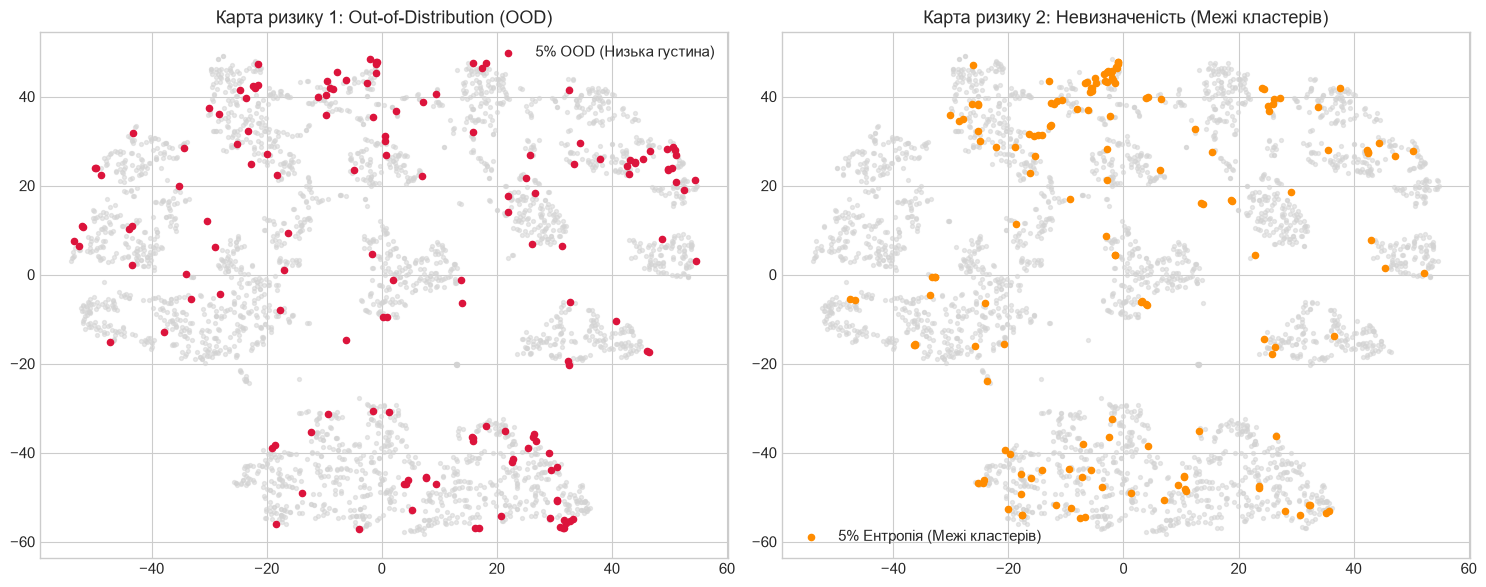

In [8]:
print("=== КРОК 4: Профілі кластерів та Дві карти ризику ===")

# 1. Профілі кластерів на вихідних ознаках X_ref_raw
global_medians = X_ref_raw.median()
global_iqrs = X_ref_raw.quantile(0.75) - X_ref_raw.quantile(0.25)

profiles = []

for c in range(BEST_C):
    mask = (gmm_labels == c)
    cluster_size = np.sum(mask)
    cluster_medians = X_ref_raw[mask].median()
    
    # Розрахунок z-scores
    z_scores = {}
    for col in X_ref_raw.columns:
        iqr = global_iqrs[col]
        if iqr > 0:
            z = (cluster_medians[col] - global_medians[col]) / iqr
        else:
            z = (X_ref_raw[mask][col] != 0).mean() - (X_ref_raw[col] != 0).mean()
        z_scores[col] = z
        
    top5 = sorted(z_scores.items(), key=lambda x: abs(x[1]), reverse=True)[:5]
    top5_str = ", ".join([f"{k} (z={v:+.2f})" for k, v in top5])
    
    profiles.append({
        'Кластер': f'C{c}',
        'Розмір (%)': f"{cluster_size / len(gmm_labels) * 100:.1f}%",
        'Топ-5 ознак': top5_str
    })

df_profiles = pd.DataFrame(profiles)
print("\nПрофілі кластерів:")
print(df_profiles.to_string(index=False))

# 2. Дві карти ризику (Risk Maps)
# Оцінюємо густину та ентропію на підвибірці для многовидів (N=3000)
scores_density = final_gmm.score_samples(X_man)
probs_sub = gmm_probs[idx_man]

# Ентропія відповідальностей: H_i = - sum(gamma * ln(gamma))
eps = 1e-12
entropy = -np.sum(probs_sub * np.log(probs_sub + eps), axis=1)

q5_density = np.quantile(scores_density, 0.05)
q95_entropy = np.quantile(entropy, 0.95)

ood_mask = scores_density <= q5_density
high_ent_mask = entropy >= q95_entropy

j_risk = len(set(np.where(ood_mask)[0]).intersection(set(np.where(high_ent_mask)[0]))) / \
         len(set(np.where(ood_mask)[0]).union(set(np.where(high_ent_mask)[0])))

print(f"\nКоефіцієнт Жаккара між OOD-точками та точками високої ентропії: {j_risk:.4f}")

# Візуалізація двох карт ризику на проєкції t-SNE
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(p_tsne[:, 0], p_tsne[:, 1], c='lightgrey', s=8, alpha=0.5)
axes[0].scatter(p_tsne[ood_mask, 0], p_tsne[ood_mask, 1], c='crimson', s=20, label='5% OOD (Низька густина)')
axes[0].set_title('Карта ризику 1: Out-of-Distribution (OOD)')
axes[0].legend()

axes[1].scatter(p_tsne[:, 0], p_tsne[:, 1], c='lightgrey', s=8, alpha=0.5)
axes[1].scatter(p_tsne[high_ent_mask, 0], p_tsne[high_ent_mask, 1], c='darkorange', s=20, label='5% Ентропія (Межі кластерів)')
axes[1].set_title('Карта ризику 2: Невизначеність (Межі кластерів)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../notebooks/risk_maps.png', dpi=300)
plt.show()

In [9]:
print("=== ЗАПЕЧАТАНИЙ КОНВЕРТ: Порівняння з Y ===")

if Y_sealed is not None:
    ari_y = adjusted_rand_score(gmm_labels, Y_sealed)
    print(f"ARI між мітками GMM та істинним Y: {ari_y:.4f}")
    
    df_contingency = pd.crosstab(
        pd.Series(gmm_labels, name='Кластер GMM'), 
        pd.Series(Y_sealed, name='Істинний Y (Дефолт)')
    )
    
    df_contingency['Частка дефолту (%)'] = (df_contingency[1] / (df_contingency[0] + df_contingency[1]) * 100).round(2)
    
    print("\nТаблиця спряженості (Contingency Table):")
    print(df_contingency)
else:
    print("Мітки Y відсутні у вхідних даних.")

=== ЗАПЕЧАТАНИЙ КОНВЕРТ: Порівняння з Y ===
ARI між мітками GMM та істинним Y: 0.1000

Таблиця спряженості (Contingency Table):
Істинний Y (Дефолт)      0     1  Частка дефолту (%)
Кластер GMM                                         
0                    92202  2771                2.92
1                      122   147               54.65
2                     8587  4572               34.74
3                    39063  2536                6.10
